# Exercise 3: Text Representation Techniques

## Aim

To implement One-Hot Encoding, Bag of Words and Word Cloud for a given corpus to prepare textual data for NLP and machine learning.

## Objective

Create a vocabulary, encode unique words, calculate term frequencies, build a Document-Term Matrix and visualize frequent terms.

## Pre-Lab Task:

### 1. What is a vocabulary in NLP?

A vocabulary is the collection of unique tokens found in the corpus.

### 2. What does One-Hot Encoding represent?

It represents one vocabulary item using a vector containing one 1 and zeros elsewhere.

### 3. What is Bag of Words?

Bag of Words represents a document by counting how often vocabulary terms occur.

### 4. What is a Document-Term Matrix?

A Document-Term Matrix has documents as rows and terms as columns, with each cell storing a count or weight.

### 5. What is a Word Cloud?

A Word Cloud visualizes terms with font sizes related to their frequencies.

### 6. What is NER?

NER finds and classifies named entities such as person, organization and location mentions.

## In- Lab Task

### Tasks

1. Create a different text corpus.
2. Generate unique vocabulary.
3. Display One-Hot vectors in a table.
4. Create a CountVectorizer model.
5. Display the Document-Term Matrix.
6. Generate a Word Cloud and list frequent words.

#### 1. Create the corpus and identify unique words.

In [1]:
corpus = ["bees visit garden flowers", "flowers attract butterflies", "garden plants need sunlight"]
tokens = [doc.lower().split() for doc in corpus]
vocabulary = sorted(set(word for doc in tokens for word in doc))
print("Corpus:", corpus)
print("Vocabulary:", vocabulary)


Corpus: ['bees visit garden flowers', 'flowers attract butterflies', 'garden plants need sunlight']
Vocabulary: ['attract', 'bees', 'butterflies', 'flowers', 'garden', 'need', 'plants', 'sunlight', 'visit']


#### 2. Generate One-Hot Encoding vectors.

In [2]:
import pandas as pd
one_hot = pd.DataFrame(
    [[int(word == item) for item in vocabulary] for word in vocabulary],
    index=vocabulary, columns=vocabulary
)
display(one_hot)

,attract,bees,butterflies,flowers,garden,need,plants,sunlight,visit
attract,1,0,0,0,0,0,0,0,0
bees,0,1,0,0,0,0,0,0,0
butterflies,0,0,1,0,0,0,0,0,0
flowers,0,0,0,1,0,0,0,0,0
garden,0,0,0,0,1,0,0,0,0
need,0,0,0,0,0,1,0,0,0
plants,0,0,0,0,0,0,1,0,0
sunlight,0,0,0,0,0,0,0,1,0
visit,0,0,0,0,0,0,0,0,1


#### 3. Build the Bag of Words model.

In [3]:
# If needed: %pip install scikit-learn
from sklearn.feature_extraction.text import CountVectorizer
vectorizer = CountVectorizer()
matrix = vectorizer.fit_transform(corpus)
print("Vocabulary:", vectorizer.get_feature_names_out())

Vocabulary: ['attract' 'bees' 'butterflies' 'flowers' 'garden' 'need' 'plants'
 'sunlight' 'visit']


#### 4. Construct the Document-Term Matrix.

In [4]:
dtm = pd.DataFrame(matrix.toarray(),
                   columns=vectorizer.get_feature_names_out(),
                   index=["D1", "D2", "D3"])
display(dtm)

,attract,bees,butterflies,flowers,garden,need,plants,sunlight,visit
D1,0,1,0,1,1,0,0,0,1
D2,1,0,1,1,0,0,0,0,0
D3,0,0,0,0,1,1,1,1,0


#### 5. Generate a Word Cloud.

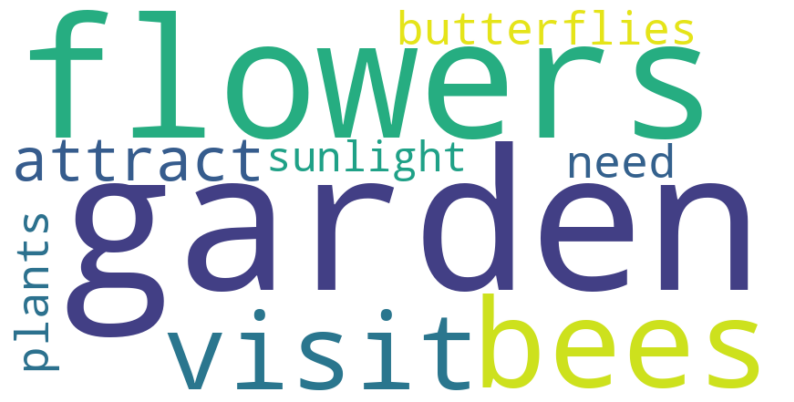

In [5]:
# If needed: %pip install wordcloud matplotlib
import matplotlib.pyplot as plt
from wordcloud import WordCloud
all_text = " ".join(corpus)
cloud = WordCloud(width=850, height=420, background_color="white").generate(all_text)
plt.figure(figsize=(10, 5))
plt.imshow(cloud, interpolation="bilinear")
plt.axis("off")
plt.show()

#### 6. Display the five most frequent terms.

In [6]:
print(dtm.sum().sort_values(ascending=False).head(5))

garden         2
flowers        2
attract        1
butterflies    1
bees           1
dtype: int64


## Post Lab

### Live Scenario: Exploring a wildlife information collection

A wildlife centre wants to see which terms appear most often in short educational descriptions. Repeat the representation workflow using this separate dataset.

#### Sample Dataset

,and,animals,at,for,forests,foxes,hunt,in,live,night,owls,provide,shelter,small
D1,0,0,0,0,1,1,0,1,1,0,0,0,0,0
D2,0,1,1,0,0,0,1,0,0,1,1,0,0,1
D3,1,0,0,1,1,1,0,0,0,0,1,1,1,0


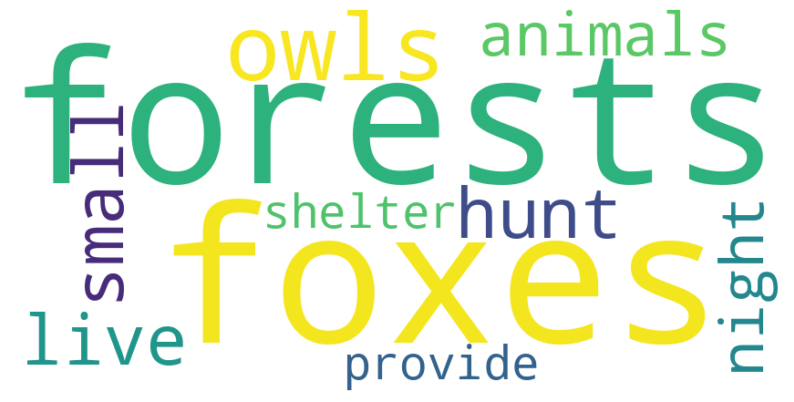

Top terms: {'forests': 2, 'foxes': 2, 'owls': 2, 'animals': 1, 'for': 1}


In [7]:
wildlife_docs = [
    "foxes live in forests",
    "owls hunt small animals at night",
    "forests provide shelter for foxes and owls"
]
wild_vectorizer = CountVectorizer()
wild_matrix = wild_vectorizer.fit_transform(wildlife_docs)
wild_dtm = pd.DataFrame(wild_matrix.toarray(),
    columns=wild_vectorizer.get_feature_names_out(), index=["D1","D2","D3"])
display(wild_dtm)
wild_cloud = WordCloud(width=850, height=420, background_color="white").generate(" ".join(wildlife_docs))
plt.figure(figsize=(10,5)); plt.imshow(wild_cloud, interpolation="bilinear"); plt.axis("off"); plt.show()
print("Top terms:", wild_dtm.sum().sort_values(ascending=False).head(5).to_dict())

## Output

The notebook displays the sorted vocabulary, a One-Hot Encoding table, the Bag-of-Words Document-Term Matrix, a Word Cloud image and the five highest-frequency terms. The vocabulary terms become the DTM column names; each row corresponds to one document.

### Report

One-Hot Encoding, Bag of Words, the Document-Term Matrix and Word Cloud were produced for the wildlife-themed corpus.

### Conclusion

Text representation converts text into numerical forms that can be inspected and used by machine learning algorithms.